# 01 数据清洗与时间规律分析（成员A）

题目四：城市电力负荷分析与预测

本 notebook 负责：数据读入、列名规整、时间解析、缺失/重复/网格完整性检查，以及日、周、季节尺度的负荷规律分析。

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Windows 下显示中文与负号
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

print('pandas', pd.__version__)
print('numpy', np.__version__)
print('matplotlib', plt.matplotlib.__version__)

pandas 3.0.5
numpy 2.5.2
matplotlib 3.11.0


## 1. 读入数据与字段规整

原始列名中 `Zone 2  Power Consumption` 含双空格，统一改成短名：

| 短名 | 原列名 |
|---|---|
| DateTime | DateTime |
| T | Temperature |
| RH | Humidity |
| WS | Wind Speed |
| GDF | general diffuse flows |
| DF | diffuse flows |
| Z1 | Zone 1 Power Consumption |
| Z2 | Zone 2  Power Consumption |
| Z3 | Zone 3  Power Consumption |

时间列格式为 **月/日/年 时:分**，解析时必须指定 `format='%m/%d/%Y %H:%M'`，否则会出现日期错位。

In [2]:
df = pd.read_csv('data/题4_城市电力负荷.csv', encoding='utf-8-sig')

# 统一列名（按位置重命名，避免原列名的双空格问题）
df.columns = ['DateTime', 'T', 'RH', 'WS', 'GDF', 'DF', 'Z1', 'Z2', 'Z3']

# 解析时间并设为索引
df['DateTime'] = pd.to_datetime(df['DateTime'], format='%m/%d/%Y %H:%M')
df = df.set_index('DateTime').sort_index()

print('shape:', df.shape)
print('时间范围:', df.index.min(), '->', df.index.max())
print('缺失值合计:', df.isna().sum().sum())
print('重复时间戳:', df.index.duplicated().sum())
df.head()

shape: (52416, 8)
时间范围: 2017-01-01 00:00:00 -> 2017-12-30 23:50:00
缺失值合计: 0
重复时间戳: 0


,T,RH,WS,GDF,DF,Z1,Z2,Z3
DateTime,,,,,,,,
2017-01-01 00:00:00,6.559,73.8,0.083,0.051,0.119,34055.69620,16128.87538,20240.96386
2017-01-01 00:10:00,6.414,74.5,0.083,0.070,0.085,29814.68354,19375.07599,20131.08434
2017-01-01 00:20:00,6.313,74.5,0.080,0.062,0.100,29128.10127,19006.68693,19668.43373
2017-01-01 00:30:00,6.121,75.0,0.083,0.091,0.096,28228.86076,18361.09422,18899.27711
2017-01-01 00:40:00,5.921,75.7,0.081,0.048,0.085,27335.69620,17872.34043,18442.40964


## 2. 时间网格完整性检查

预期：2017-01-01 00:00 至 2017-12-30 23:50，每 10 分钟一个点，共 364 × 144 = 52,416 行，无缺失、无重复。

In [3]:
full_grid = pd.date_range(df.index.min(), df.index.max(), freq='10min')

print('应有时间点:', len(full_grid))
print('实际行数:', len(df))
print('缺失时间点:', len(full_grid.difference(df.index)))
print('覆盖天数:', df.index.normalize().nunique())

应有时间点: 52416
实际行数: 52416
缺失时间点: 0
覆盖天数: 364


## 3. 数值字段概况

下一步：用 `describe()` 和箱线图检查异常值，重点记录风速（WS）的双峰分布现象。

In [4]:
df.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
T,52416.0,18.810,5.815,3.247,14.410,18.780,22.890,40.010
RH,52416.0,68.260,15.551,11.340,58.310,69.860,81.400,94.800
WS,52416.0,1.959,2.349,0.050,0.078,0.086,4.915,6.483
GDF,52416.0,182.697,264.401,0.004,0.062,5.036,319.600,1163.000
DF,52416.0,75.028,124.211,0.011,0.122,4.456,101.000,936.000
Z1,52416.0,32344.971,7130.563,13895.696,26310.669,32265.920,37309.018,52204.395
Z2,52416.0,21042.509,5201.466,8560.081,16980.766,20823.168,24713.718,37408.861
Z3,52416.0,17835.406,6622.165,5935.174,13129.327,16415.117,21624.100,47598.326


## 4. 负荷的时间规律

从三个尺度分析：**季节**（月）、**星期**（工作日/周末、周内分布）、**日内**（24 小时曲线）。
三个分区用固定配色：分区1 蓝色、分区2 橙色、分区3 绿色。


In [5]:
# 供后面所有图使用的派生字段
work = df[['Z1', 'Z2', 'Z3']].copy()
work['hour'] = work.index.hour
work['month'] = work.index.month
work['dow'] = work.index.dayofweek          # 0=周一, 6=周日
work['is_weekend'] = work['dow'] >= 5
work['date'] = work.index.date

# 三个尺度的聚合表
hourly = work.groupby('hour')[['Z1', 'Z2', 'Z3']].mean()
monthly = work.groupby('month')[['Z1', 'Z2', 'Z3']].mean()
by_daytype = work.groupby('is_weekend')[['Z1', 'Z2', 'Z3']].mean()

print('各分区日负荷峰值小时:', hourly.idxmax().to_dict())
print('各分区日负荷谷值小时:', hourly.idxmin().to_dict())
print()
print('工作日/周末日均负荷 (False=工作日, True=周末):')
print(by_daytype.round(0))
print()
print('周末相对工作日的差异 (%):')
print(((by_daytype.loc[True] / by_daytype.loc[False] - 1) * 100).round(2))
print()
print('各分区月均负荷最高/最低月份:', monthly.idxmax().to_dict(), monthly.idxmin().to_dict())
print(monthly.round(0))

各分区日负荷峰值小时: {'Z1': 20, 'Z2': 20, 'Z3': 20}
各分区日负荷谷值小时: {'Z1': 6, 'Z2': 6, 'Z3': 7}

工作日/周末日均负荷 (False=工作日, True=周末):
                 Z1       Z2       Z3
is_weekend                           
False       32676.0  21546.0  17776.0
True        31517.0  19783.0  17983.0

周末相对工作日的差异 (%):
Z1   -3.55
Z2   -8.19
Z3    1.16
dtype: float64

各分区月均负荷最高/最低月份: {'Z1': 8, 'Z2': 8, 'Z3': 7} {'Z1': 11, 'Z2': 4, 'Z3': 12}
            Z1       Z2       Z3
month                           
1      31032.0  19394.0  17746.0
2      30986.0  18788.0  17335.0
3      31155.0  18458.0  16948.0
4      31170.0  17634.0  18593.0
5      32396.0  19977.0  17621.0
6      34606.0  20671.0  20431.0
7      35832.0  24148.0  28194.0
8      36435.0  24656.0  24649.0
9      33397.0  20180.0  14923.0
10     32828.0  21469.0  13264.0
11     29002.0  23240.0  12862.0
12     29024.0  23682.0  11045.0


### 图 A1　全年日均负荷

10 分钟数据一年有 5 万多个点，直接画会糊成一片，所以先按天求均值。用于观察季节趋势和分区差异。

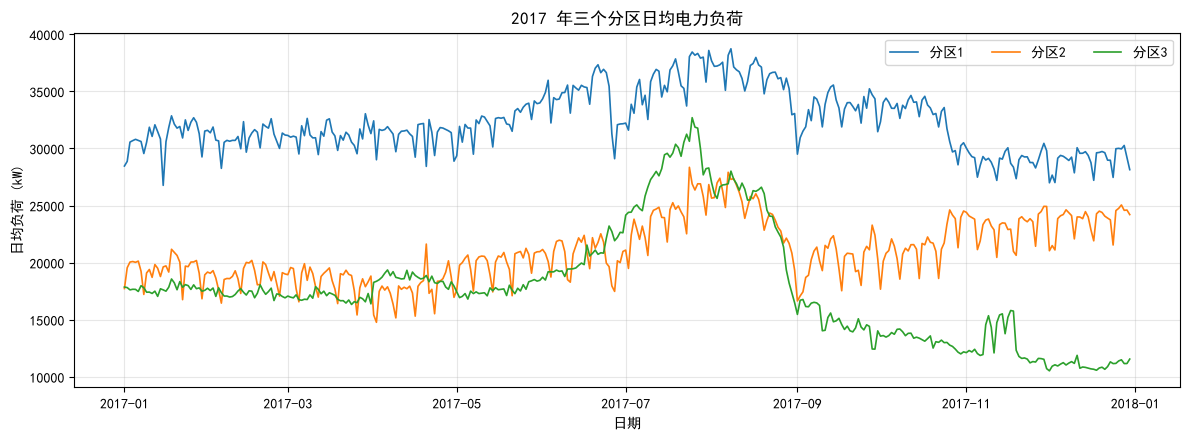

In [6]:
daily = df[['Z1', 'Z2', 'Z3']].resample('D').mean()

colors = {'Z1': '#1f77b4', 'Z2': '#ff7f0e', 'Z3': '#2ca02c'}
labels = {'Z1': '分区1', 'Z2': '分区2', 'Z3': '分区3'}

fig, ax = plt.subplots(figsize=(12, 4.5))
for c in ['Z1', 'Z2', 'Z3']:
    ax.plot(daily.index, daily[c], color=colors[c], lw=1.2, label=labels[c])
ax.set_title('2017 年三个分区日均电力负荷')
ax.set_xlabel('日期')
ax.set_ylabel('日均负荷 (kW)')
ax.legend(ncol=3)
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig('figures/fig_A1_yearly.png', dpi=300, bbox_inches='tight')
plt.show()

### 图 A2　24 小时平均负荷曲线（工作日 vs 周末）

左：工作日，右：周末。横轴为小时，纵轴为该小时的平均负荷。用于识别早晚高峰和日周期。

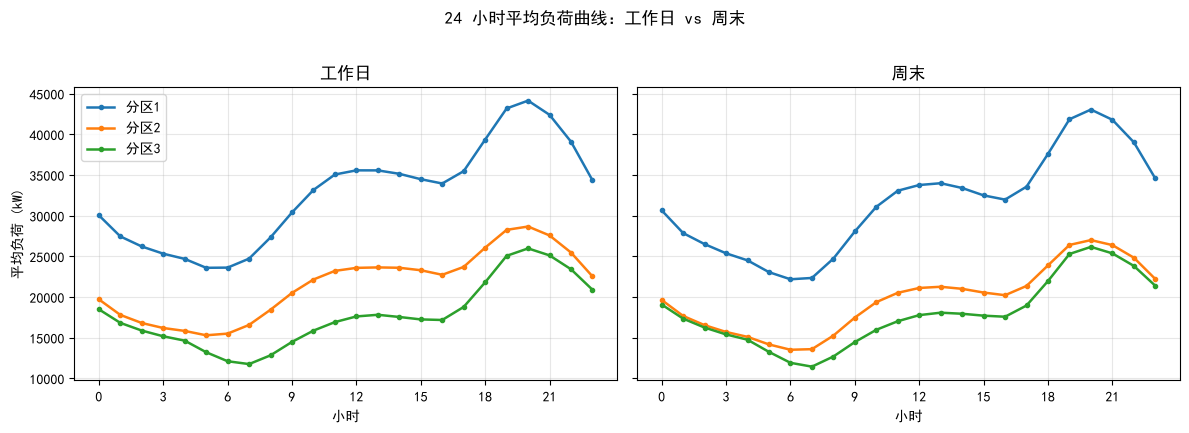

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, we, title in zip(axes, [False, True], ['工作日', '周末']):
    sub = work[work['is_weekend'] == we].groupby('hour')[['Z1', 'Z2', 'Z3']].mean()
    for c in ['Z1', 'Z2', 'Z3']:
        ax.plot(sub.index, sub[c], color=colors[c], lw=1.8, marker='o', ms=3, label=labels[c])
    ax.set_title(title)
    ax.set_xlabel('小时')
    ax.set_xticks(range(0, 24, 3))
    ax.grid(alpha=0.3)
axes[0].set_ylabel('平均负荷 (kW)')
axes[0].legend()
fig.suptitle('24 小时平均负荷曲线：工作日 vs 周末', y=1.02)
fig.tight_layout()
fig.savefig('figures/fig_A2_hourly.png', dpi=300, bbox_inches='tight')
plt.show()

### 图 A3　月度平均负荷（季节尺度）

用于比较三个分区的季节特征。

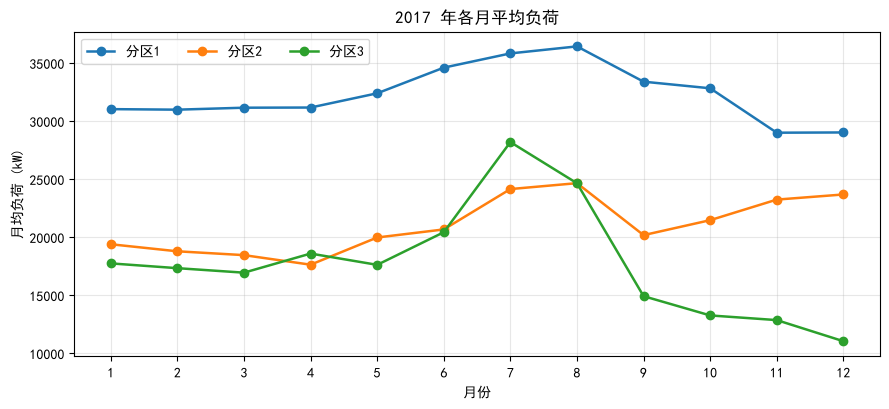

In [8]:
fig, ax = plt.subplots(figsize=(9, 4.2))
for c in ['Z1', 'Z2', 'Z3']:
    ax.plot(monthly.index, monthly[c], color=colors[c], lw=1.8, marker='o', label=labels[c])
ax.set_title('2017 年各月平均负荷')
ax.set_xlabel('月份')
ax.set_ylabel('月均负荷 (kW)')
ax.set_xticks(range(1, 13))
ax.grid(alpha=0.3)
ax.legend(ncol=3)
fig.tight_layout()
fig.savefig('figures/fig_A3_monthly.png', dpi=300, bbox_inches='tight')
plt.show()

### 图 A4　日 × 小时负荷热力图（分区1）

纵轴为日期，横轴为小时，颜色越深负荷越高。能同时看到日周期和季节变化，也能发现异常日。

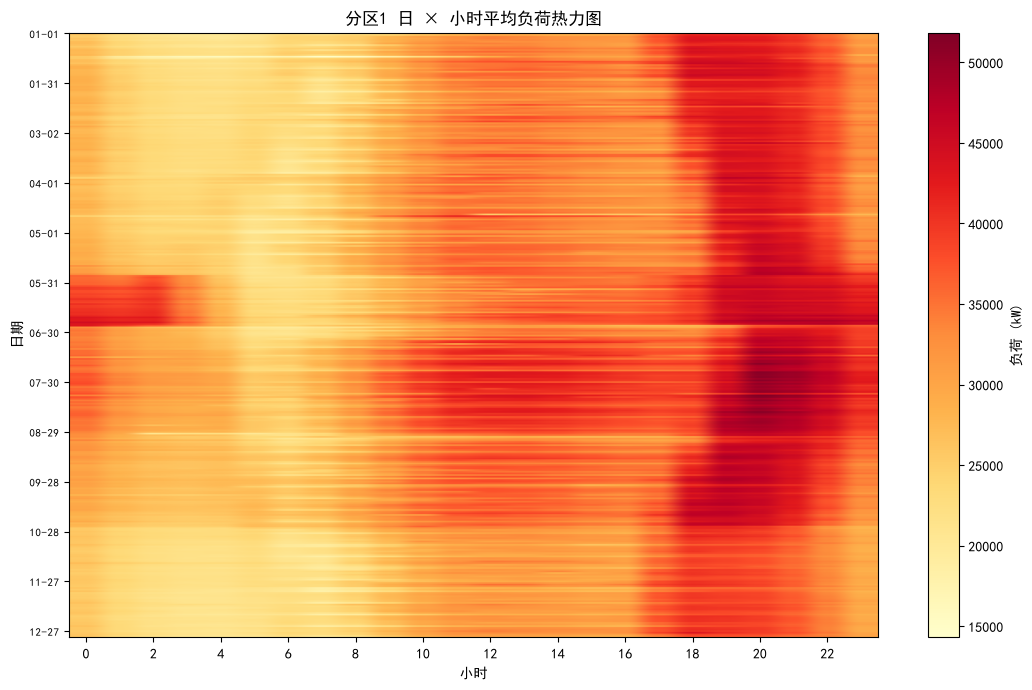

In [9]:
pivot = work.groupby(['date', 'hour'])['Z1'].mean().unstack()
pivot = pivot.reindex(columns=range(24))

fig, ax = plt.subplots(figsize=(11, 7))
im = ax.imshow(pivot.values, aspect='auto', cmap='YlOrRd', origin='upper')
ax.set_xticks(range(0, 24, 2))
ax.set_xticklabels(range(0, 24, 2))

step = 30
ax.set_yticks(range(0, len(pivot), step))
ax.set_yticklabels([pivot.index[i].strftime('%m-%d') for i in range(0, len(pivot), step)], fontsize=8)

ax.set_xlabel('小时')
ax.set_ylabel('日期')
ax.set_title('分区1 日 × 小时平均负荷热力图')
cbar = fig.colorbar(im, ax=ax)
cbar.set_label('负荷 (kW)')
fig.tight_layout()
fig.savefig('figures/fig_A4_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

### 图 A5　周内分布（周一至周日）

对每个星期几，画出该天日均负荷的箱线图，用于观察周尺度的规律和工作日/周末差异。

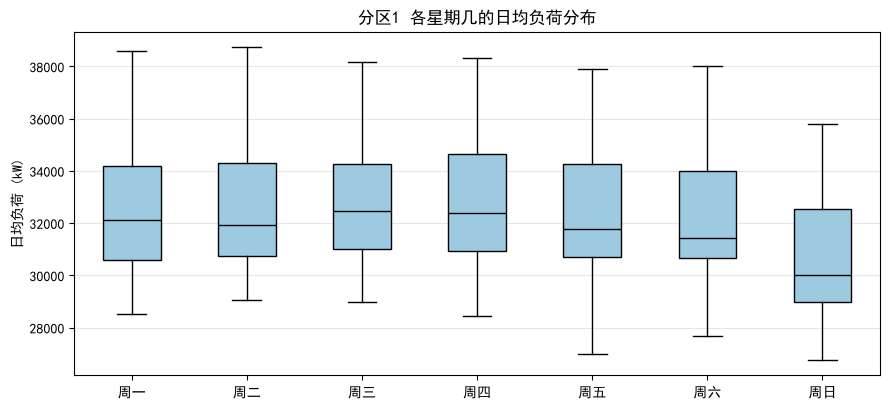

In [10]:
daily_z1 = work['Z1'].resample('D').mean().to_frame('Z1')
daily_z1['dow'] = daily_z1.index.dayofweek

data = [daily_z1.loc[daily_z1['dow'] == i, 'Z1'].values for i in range(7)]

fig, ax = plt.subplots(figsize=(9, 4.2))
bp = ax.boxplot(data, tick_labels=['周一', '周二', '周三', '周四', '周五', '周六', '周日'],
                patch_artist=True, medianprops=dict(color='black'))
for patch in bp['boxes']:
    patch.set_facecolor('#9ecae1')
ax.set_title('分区1 各星期几的日均负荷分布')
ax.set_ylabel('日均负荷 (kW)')
ax.grid(axis='y', alpha=0.3)
fig.tight_layout()
fig.savefig('figures/fig_A5_weekday.png', dpi=300, bbox_inches='tight')
plt.show()

## 5. 供报告引用的关键数字

跑完上面所有 cell 后，把这里的输出抄进报告第 4 章，**不要凭印象写**。

In [11]:
summary = pd.DataFrame({
    '日均负荷': work[['Z1', 'Z2', 'Z3']].mean(),
    '日峰值小时': hourly.idxmax(),
    '日谷值小时': hourly.idxmin(),
    '最高月': monthly.idxmax(),
    '最低月': monthly.idxmin(),
    '周末相对工作日变化%': ((by_daytype.loc[True] / by_daytype.loc[False] - 1) * 100).round(2),
})
summary

,日均负荷,日峰值小时,日谷值小时,最高月,最低月,周末相对工作日变化%
Z1,32344.970564,20,6,8,11,-3.55
Z2,21042.509082,20,6,8,4,-8.19
Z3,17835.406218,20,7,7,12,1.16


### 图 A6　风速分布（数据质量检查用）

风速呈现明显的**双峰分布**。IQR 和 3σ 都检测不出异常点，因为双峰把四分位距撑大了——这说明"统计检验没报警"不等于"数据没问题"，必须结合直方图和业务含义判断。


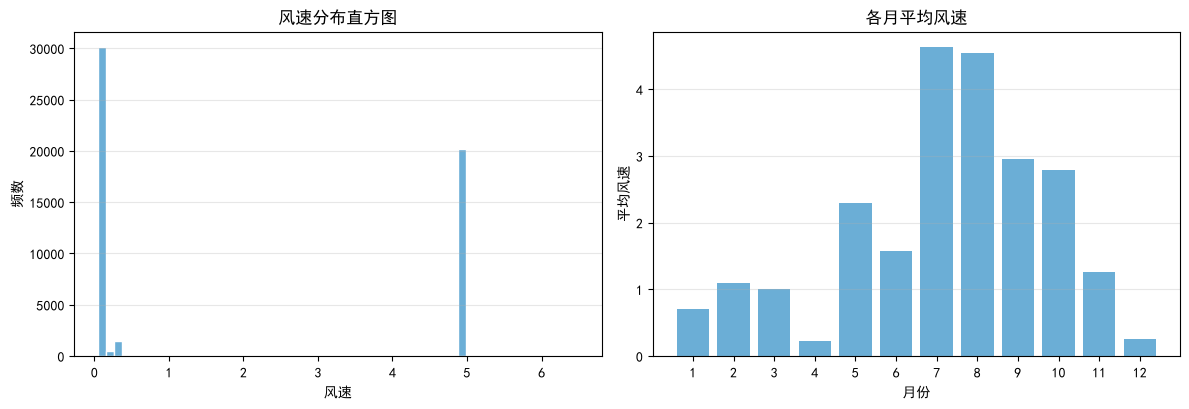

风速 < 0.2 的占比: 57.6%
风速 >= 4.8 的占比: 38.6%
冬季(1-2月)均值: 0.89
夏季(7-8月)均值: 4.58


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

# 左：直方图
axes[0].hist(df['WS'], bins=60, color='#6baed6', edgecolor='white')
axes[0].set_title('风速分布直方图')
axes[0].set_xlabel('风速')
axes[0].set_ylabel('频数')
axes[0].grid(axis='y', alpha=0.3)

# 右：月度均值
ws_month = df['WS'].groupby(df.index.month).mean()
axes[1].bar(ws_month.index, ws_month.values, color='#6baed6')
axes[1].set_title('各月平均风速')
axes[1].set_xlabel('月份')
axes[1].set_ylabel('平均风速')
axes[1].set_xticks(range(1, 13))
axes[1].grid(axis='y', alpha=0.3)

fig.tight_layout()
fig.savefig('figures/fig_A6_windspeed.png', dpi=300, bbox_inches='tight')
plt.show()

low = (df['WS'] < 0.2).mean() * 100
high = (df['WS'] >= 4.8).mean() * 100
print(f'风速 < 0.2 的占比: {low:.1f}%')
print(f'风速 >= 4.8 的占比: {high:.1f}%')
print('冬季(1-2月)均值:', round(df.loc['2017-01':'2017-02', 'WS'].mean(), 2))
print('夏季(7-8月)均值:', round(df.loc['2017-07':'2017-08', 'WS'].mean(), 2))